# Seismic waveforms: QC, filtering and first picks

**Question:** How do filter band, seeded noise and STA/LTA threshold change P/S pick residuals on the same STEAD-derived trace?
**Level 1 — Foundations and measurement** · 45–60 min

## Objectives
- Inspect provenance, units, channel order, sampling and analyst-reference labels.
- Apply the product Butterworth filter and classical STA/LTA detector using editable controls.
- Measure pick residuals against analyst references while varying synthetic noise, passband and trigger threshold.

## Setup

Run from repository root in the pinned notebook environment:
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8

The experiment cell prints active package versions.

## Data
Input: one trace from the committed STEAD-derived browser subset. Source: Mousavi et al., Stanford Earthquake Dataset (STEAD), [official repository](https://github.com/smousavi05/STEAD), DOI [10.1109/ACCESS.2019.2947848](https://doi.org/10.1109/ACCESS.2019.2947848), licensed CC BY 4.0 ([license](https://github.com/smousavi05/STEAD/blob/master/LICENSE)). The selected trace is a modified derivative: source ZNE channels are reordered ENZ, mean-removed and divided by peak absolute count, with seeded noise added in this lesson. Samples are normalized, unrestituted counts; no physical ground-motion units are available. Analyst picks are references, not geological truth. Added noise is synthetic and seeded. No result describes a new field observation.

**Attribution:** Mousavi et al. (2019), STEAD, CC BY 4.0. This selected derivative reorders ZNE to ENZ and applies mean removal and peak normalization; this notebook additionally adds seeded synthetic noise. No instrument response or physical-unit conversion is represented.

## Method

For sample interval Δt and index n, time is tₙ=nΔt. Inspect acquisition and data contracts before filtering: a plausible trace cannot repair wrong component orientation, clock, response or datum.

The product path in data-pipeline/waveform_processing.py removes instrument response when MiniSEED and StationXML permit, applies an SOS Butterworth band-pass with forward-backward filtering, then forms a short/long-window energy ratio. For three components x[n], the characteristic is approximately C[n]=STA(Σc x_c²)/LTA(Σc x_c²). An upward threshold crossing marks an onset. The second sufficiently separated crossing is provisionally called S; STA/LTA is not a phase classifier.

This browser trace is already normalized and has no response metadata. We call the product `waveform_processing.filter_products` SOS Butterworth implementation and use its actual STA/LTA picker, but do not load the waveform engine's pinned ObsPy contract or execute raw MiniSEED ingestion, response correction or complete M08 QC. Add one seeded standard-normal realization at several fractions of trace standard deviation. Compare picks with supplied analyst references; absolute residuals and misses are agreement diagnostics on one trace, not accuracy estimates.

### Questions
1. Which channel/window dominates the energy ratio, and what does the filter remove?
2. Does a higher threshold reduce early triggers or miss an annotated onset?
3. Why does smaller analyst-pick residual not establish physical accuracy?

### Experiment 1 — edit controls and compare the sweep

Noise settings reuse one seeded realization to isolate amplitude. Filter and trigger controls vary separately. Set the band to None to bypass filtering.

In [1]:
from importlib.metadata import version

print("Runtime versions:", {name: version(name) for name in ["numpy", "scipy", "matplotlib"]})
# Reproducible notebook experiment cell.
from pathlib import Path
import json, sys, os, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
from phase_picking import classical_stalta_picks

base = root / "data/derived/phase/browser-assets/stead"
manifest = json.loads((base / "manifest.json").read_text(encoding="utf-8"))
record = manifest["records"][0]
raw = (
    np.fromfile(base / record["waveform_file"], dtype="<f4")
    .reshape(manifest["input"]["shape"])[0]
    .T.astype(float)
)
fs = float(manifest["input"]["sample_rate_hz"])
dt = 1 / fs


Runtime versions: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}


### The trace metadata supplies three ordered components, a sample rate, analyst P/S reference times, and the frozen benchmark parameters. Those references support residual calculations for this trace, but they are annotations rather than independent event-time truth. The next calculations therefore measure detector sensitivity on a labeled example, not network-wide accuracy.

El registro aporta tres componentes ordenadas, frecuencia de muestreo, tiempos de referencia P/S y parámetros congelados del benchmark. Esas referencias permiten calcular residuos para esta traza, pero son anotaciones y no una verdad temporal independiente. Los cálculos siguientes miden sensibilidad del detector en un ejemplo etiquetado, no exactitud en toda una red.

In [2]:
# Preserve the seed so each filter and threshold change sees the same noise realization.
labels = {"P": record["analyst_p_s"], "S": record["analyst_s_s"]}
bench = json.loads((root / "data/derived/phase/stead-heldout-benchmark.json").read_text(encoding="utf-8"))
pars = bench["classical_parameters"]
print(
    "Trace",
    record["trace_id"],
    raw.shape,
    "sample x component; fs=",
    fs,
    "Hz; units=",
    manifest["input"]["unit"],
)
print("Channels", manifest["input"]["component_order"], "| analyst reference times (s):", labels)
FILTER_BAND_HZ = (1.0, 12.0)  # set None to bypass
ADDED_NOISE_FRACTION = 0.25  # relative to trace standard deviation
TRIGGER_RATIO = float(pars["trigger_ratio"])
STA_SECONDS = float(pars["STA_s"])
LTA_SECONDS = float(pars["LTA_s"])
MINIMUM_PS_SECONDS = float(pars["minimum_PS_s"])
SEED = 20261027
noise_unit = np.random.default_rng(SEED).standard_normal(raw.shape)
noise = noise_unit * np.std(raw)


Trace B917.PB_20110107214856_EV (6000, 3) sample x component; fs= 100.0 Hz; units= dimensionless normalized instrument counts
Channels ['E', 'N', 'Z'] | analyst reference times (s): {'P': 7.0, 'S': 12.77}


### The fourth-order Butterworth filter is represented as second-order sections to limit numerical sensitivity. Zero-phase forward/backward filtering preserves onset timing away from the edges; the computed padding length marks the interval where transients can contaminate picks. Comparing the unfiltered and filtered traces makes that assumption inspectable.

El filtro Butterworth de cuarto orden se representa mediante secciones de segundo orden para reducir sensibilidad numérica. El filtrado de fase cero conserva los tiempos de inicio lejos de los bordes; el relleno calculado señala dónde los transitorios pueden contaminar las detecciones. La comparación entre trazas filtradas y originales permite inspeccionar esa hipótesis.

In [3]:
# Run the product filter in its pinned pipeline runtime; the notebook kernel omits ObsPy.
from pathlib import Path
import os, subprocess

filter_work = Path(os.environ["CAOS_TEMP_ROOT"]) / "caos-waveform-filter"
filter_work.mkdir(parents=True, exist_ok=True)
filter_input = filter_work / "filter-input.npy"
filter_output = filter_work / "filter-output.npy"
filter_meta = filter_work / "filter-meta.json"
filter_engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
filter_engine = filter_engine_root / ".venv-m08" / "Scripts" / "python.exe"
if not filter_engine.is_file():
    raise RuntimeError("The pinned M08 product interpreter is required for waveform filtering.")
filter_child = "\n".join([
    "import json, numpy as np, sys",
    "from pathlib import Path",
    "sys.path.insert(0, str(Path(sys.argv[1]) / 'data-pipeline'))",
    "from waveform_processing import filter_products",
    "x = np.load(sys.argv[2])",
    "y = np.empty_like(x)",
    "pads = []",
    "for c in range(x.shape[1]):",
    "    y[:, c], sos, pad = filter_products(x[:, c], float(sys.argv[4]), (float(sys.argv[5]), float(sys.argv[6])), 4)",
    "    pads.append(pad)",
    "np.save(sys.argv[3], y)",
    "Path(sys.argv[7]).write_text(json.dumps({'pads': pads}), encoding='utf-8')",
])

def condition(values, band):
    if band is None:
        return values.copy(), 0
    np.save(filter_input, values)
    done = subprocess.run(
        [str(filter_engine), "-c", filter_child, str(filter_engine_root), str(filter_input), str(filter_output), str(fs), str(band[0]), str(band[1]), str(filter_meta)],
        cwd=filter_engine_root, capture_output=True, text=True, timeout=60,
    )
    if done.returncode:
        raise RuntimeError(done.stderr[-3000:])
    meta = json.loads(filter_meta.read_text(encoding="utf-8"))
    return np.load(filter_output), max(meta["pads"])


### This experiment adds seeded Gaussian noise before calling the product STA/LTA picker. The short and long windows define the energy ratio, while the minimum P-S separation constrains which later trigger may be labeled S. A missing trigger remains a miss; a second trigger is only a candidate under this rule.

Este experimento agrega ruido gaussiano con semilla fija antes de llamar al detector STA/LTA del producto. Las ventanas corta y larga definen la razón de energía, y la separación mínima P-S limita qué detección posterior puede etiquetarse como S. Una detección ausente sigue siendo un fallo; la segunda es solo candidata bajo esta regla.

In [4]:
# Run STA/LTA picking for one filter, noise level, and trigger threshold.
def trial(band, noise_fraction, threshold):
    filtered, pad = condition(raw + noise_fraction * noise, band)
    picks = classical_stalta_picks(
        filtered,
        sample_interval_s=dt,
        threshold=threshold,
        sta_s=STA_SECONDS,
        lta_s=LTA_SECONDS,
        minimum_ps_s=MINIMUM_PS_SECONDS,
    )
    row = {
        "band_Hz": "off" if band is None else f"{band[0]:g}-{band[1]:g}",
        "added_noise_fraction": noise_fraction,
        "threshold": threshold,
        "filter_pad_samples": pad,
    }
    for phase in ("P", "S"):
        t = picks[phase]
        row[f"{phase}_pick_s"] = np.nan if t is None else t
        row[f"{phase}_abs_residual_s"] = np.nan if t is None else abs(t - labels[phase])
        row[f"{phase}_detected"] = t is not None
    return filtered, picks, row


### The five rows vary filtering, noise amplitude, and trigger threshold. The first three rows isolate the filter and then the added-noise effect; the last two change several conditions together, so they are stress cases rather than a one-factor causal comparison. Read P and S residuals beside detection flags to distinguish timing error from a missed phase.

Las cinco filas varían filtrado, amplitud de ruido y umbral. Las tres primeras aíslan el efecto del filtro y luego del ruido; las dos últimas cambian varias condiciones a la vez, por lo que son pruebas de estrés y no una comparación causal de un solo factor. Lea los residuos P y S junto con las banderas para distinguir error temporal de fase omitida.

In [5]:
# Evaluate the predefined filter and noise controls without changing their labels.
configs = [
    (None, 0, TRIGGER_RATIO),
    ((1, 12), 0, TRIGGER_RATIO),
    ((1, 12), 0.25, TRIGGER_RATIO),
    ((3, 10), 0.75, TRIGGER_RATIO),
    ((3, 10), 0.75, 3.2),
]
table = pd.DataFrame([trial(*cfg)[2] for cfg in configs])
display(table.round(4))
selected, picks, _ = trial(FILTER_BAND_HZ, ADDED_NOISE_FRACTION, TRIGGER_RATIO)
print(
    "Selected controls:",
    FILTER_BAND_HZ,
    ADDED_NOISE_FRACTION,
    TRIGGER_RATIO,
    "STA/LTA/min P-S:",
    STA_SECONDS,
    LTA_SECONDS,
    MINIMUM_PS_SECONDS,
    "seed:",
    SEED,
)
print("Selected picks (s):", picks)


,band_Hz,added_noise_fraction,threshold,filter_pad_samples,P_pick_s,P_abs_residual_s,P_detected,S_pick_s,S_abs_residual_s,S_detected
0,off,0.00,2.5,0,1.19,5.81,True,7.02,5.75,True
1,1-12,0.00,2.5,27,1.19,5.81,True,6.95,5.82,True
2,1-12,0.25,2.5,27,6.99,0.01,True,12.81,0.04,True
3,3-10,0.75,2.5,27,4.55,2.45,True,5.50,7.27,True
4,3-10,0.75,3.2,27,7.02,0.02,True,12.81,0.04,True


Selected controls: (1.0, 12.0) 0.25 2.5 STA/LTA/min P-S: 0.12 1.2 0.4 seed: 20261027
Selected picks (s): {'P': 6.99, 'S': 12.81}


### A reported P or S time is a trigger candidate from one STEAD-derived waveform. Compare it with the analyst reference and with the noise and threshold rows; do not interpret a visually plausible onset as a validated pick. The candidate S rule can select a later unrelated arrival, which requires waveform and phase-context review.

Cada tiempo P o S informado es una detección candidata en una forma de onda derivada de STEAD. Compárelo con la referencia y con las filas de ruido y umbral; una llegada visualmente plausible no constituye una detección validada. La regla de S puede elegir una llegada posterior no relacionada y requiere revisar la forma de onda y su contexto de fase.

In [6]:
# State what missing and provisional arrivals mean for this synthetic trace.
print("Missing pick means missed onset; the second eligible trigger is only provisionally named S.")


Missing pick means missed onset; the second eligible trigger is only provisionally named S.


### Diagnostic 2 — inspect the selected trace and measured timing outcomes

Markers show supplied analyst references and detector output. The displayed trace follows the selected noise and filter controls. Compare the numeric residual table, not just the plot.

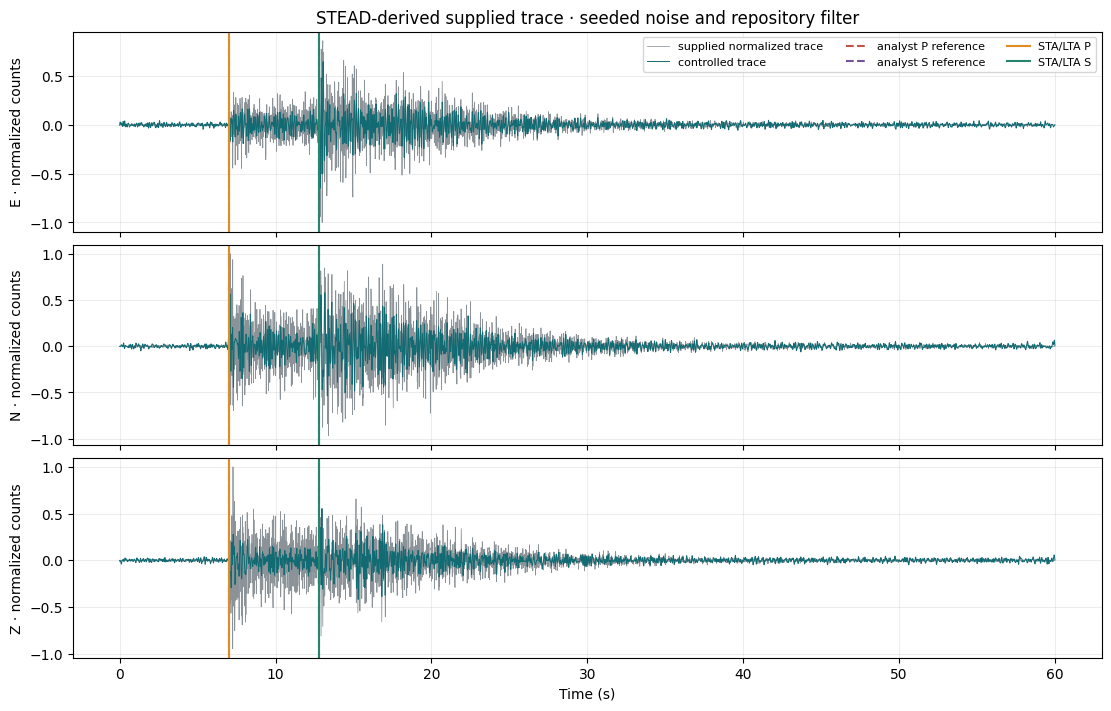

Single-trace analyst agreement is not a population score or field-truth claim.


In [7]:
# Reproducible notebook experiment cell.
time_s = np.arange(len(raw)) * dt
names = manifest["input"]["component_order"]
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
for c, ax in enumerate(axes):
    ax.plot(time_s, raw[:, c], color="#8b9398", lw=0.55, label="supplied normalized trace")
    ax.plot(time_s, selected[:, c], color="#126b73", lw=0.7, label="controlled trace")
    ax.axvline(labels["P"], color="#c45442", ls="--", label="analyst P reference")
    ax.axvline(labels["S"], color="#76529b", ls="--", label="analyst S reference")
    for phase, color in (("P", "#e28b22"), ("S", "#24866c")):
        if picks[phase] is not None:
            ax.axvline(picks[phase], color=color, label=f"STA/LTA {phase}")
    ax.set_ylabel(f"{names[c]} · normalized counts")
    ax.grid(alpha=0.22)
axes[0].legend(ncol=3, fontsize=8)
axes[-1].set_xlabel("Time (s)")
axes[0].set_title("STEAD-derived supplied trace · seeded noise and repository filter")
plt.show()
print("Single-trace analyst agreement is not a population score or field-truth claim.")


### Figure interpretation

The three panels retain component orientation and normalized-count units while overlaying the raw and controlled waveforms, analyst references, and STA/LTA candidates. The selected filter/noise run gives P=6.99 s and S=12.81 s against 7.00 s and 12.77 s references. Timing agreement on this one trace does not estimate network precision or validate the provisional S rule.

In [8]:
# Execute the product STA/LTA picker on the measured vertical component.
pick_reference = classical_stalta_picks(
    raw,
    sample_interval_s=dt,
    threshold=pars["trigger_ratio"],
    sta_s=pars["STA_s"],
    lta_s=pars["LTA_s"],
    minimum_ps_s=pars["minimum_PS_s"],
)
print("product picker P/S candidates", pick_reference)


product picker P/S candidates {'P': 1.19, 'S': 7.0200000000000005}


### Welch spectrum

This cell executes a public pipeline operation on the declared inputs.   


In [9]:
# Change only STA/LTA threshold while holding the real trace and windows fixed.
pick_high_threshold = classical_stalta_picks(
    raw,
    sample_interval_s=dt,
    threshold=pars["trigger_ratio"] * 1.25,
    sta_s=pars["STA_s"],
    lta_s=pars["LTA_s"],
    minimum_ps_s=pars["minimum_PS_s"],
)
print("higher-threshold candidates", pick_high_threshold)


higher-threshold candidates {'P': 1.19, 'S': 7.0200000000000005}


### STA/LTA characteristic

This cell executes a public pipeline operation on the declared inputs.   


In [10]:
# Change only the short window to inspect detector sensitivity on identical samples.
pick_short_sta = classical_stalta_picks(
    raw,
    sample_interval_s=dt,
    threshold=pars["trigger_ratio"],
    sta_s=pars["STA_s"] * 0.75,
    lta_s=pars["LTA_s"],
    minimum_ps_s=pars["minimum_PS_s"],
)
print("short-STA candidates", pick_short_sta)


short-STA candidates {'P': 1.19, 'S': 7.0200000000000005}




## Results

**Answer:** On the selected STEAD-derived trace, filtering and seeded noise yield P=6.99 s and S=12.81 s against analyst references 7.00 s and 12.77 s. The absolute residuals are 0.01 s and 0.04 s; this single trace is not a population score.

## Summary

The threshold/filter sweep changes candidate detections on one labeled three-component trace. Its P residual is small, but the provisional S candidate is only 0.04 s from the analyst time under this rule; neither value establishes network accuracy or validates phase identity.

## References

- [ObsPy Stream and waveform metadata](https://docs.obspy.org/packages/autogen/obspy.core.stream.stream.html)
- Committed trace and provenance manifest: data/derived/phase/browser-assets/stead/manifest.json
- Product filter design: data-pipeline/waveform_processing.py
- Product detector: data-pipeline/phase_picking.py

**Answer:** On the selected STEAD-derived trace, the filtered/noisy detector picks P=6.99 s and S=12.81 s against analyst references 7.00 s and 12.77 s: absolute residuals are 0.01 s and 0.04 s. This is one trace, not population accuracy.
